In [20]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import json

2026-01-15 13:35:21 [INFO] adopt2g.inference: Loading ensemble from /home/michele/workdir/ADOPT2g/models/seed887_n7/manifest.json...
2026-01-15 13:35:21 [INFO] adopt2g.inference:   Ensemble ID: seed887_n7
2026-01-15 13:35:21 [INFO] adopt2g.inference:   Ensemble size: 7
2026-01-15 13:35:21 [INFO] adopt2g.inference:   Calibration factor: 10.3461
2026-01-15 13:35:21 [INFO] adopt2g.inference:   Loading ESM model to cuda...
2026-01-15 13:35:22 [WARNING] adopt2g.embeddings: Flash Attention 2 not available (libcudart.so.12: cannot open shared object file: No such file or directory), falling back to sdpa attention
Some weights of EsmModel were not initialized from the model checkpoint at facebook/esm2_t33_650M_UR50D and are newly initialized: ['pooler.dense.bias', 'pooler.dense.weight']
You should probably TRAIN this model on a down-stream task to be able to use it for predictions and inference.
/home/michele/miniforge3/envs/adopt2g/lib/python3.12/site-packages/torch/cuda/__init__.py:283: User

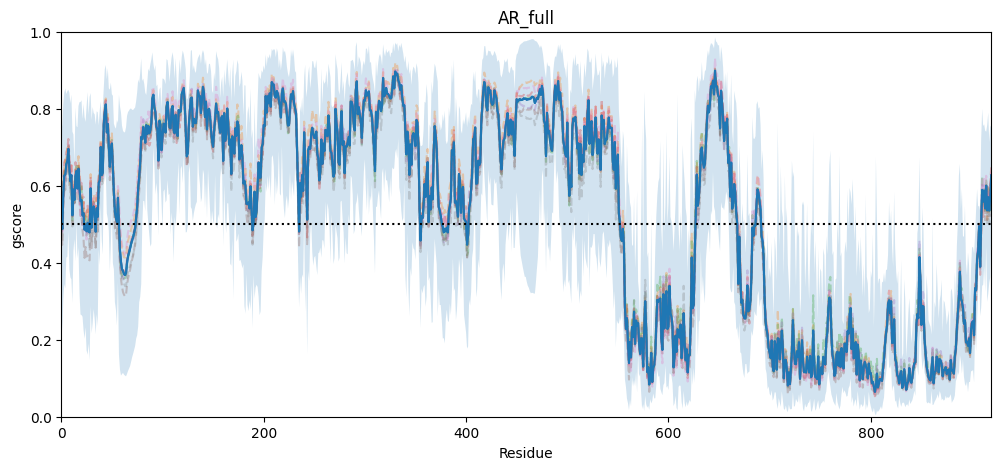

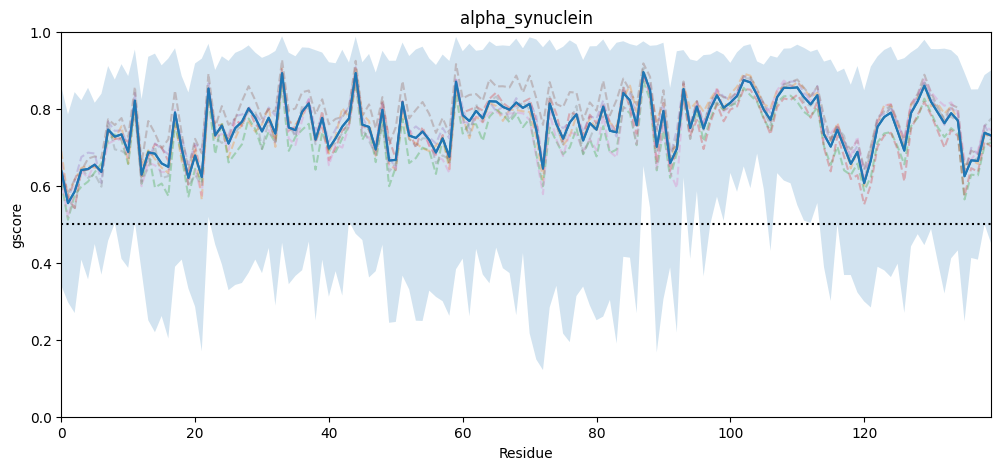

In [21]:
!adopt2g-predict --input ar.fasta --out ar-adopt2g.csv --save

df = pd.read_csv(
    "ar-adopt2g.csv",
    index_col="label",
    converters={
        "gscores": lambda x: np.asarray(json.loads(x), dtype=float),
        "gscores_lower": lambda x: np.asarray(json.loads(x), dtype=float),
        "gscores_upper": lambda x: np.asarray(json.loads(x), dtype=float),
        "member_gscores": lambda x: np.asarray(json.loads(x), dtype=float),
    },
)

for label, row in df.iterrows():
    gscores = row["gscores"]
    gscores_lower = row["gscores_lower"]
    gscores_upper = row["gscores_upper"]
    member_gscores = row["member_gscores"]

    plt.figure(figsize=(12, 5))
    plt.title(label)
    plt.plot(gscores)
    plt.fill_between(range(len(gscores)), gscores_lower, gscores_upper, alpha=0.2)
    plt.plot(member_gscores.T, alpha=0.3, ls="--")
    plt.plot(gscores, c="C0")
    plt.axhline(0.5, color="k", linestyle=":")
    plt.ylim(0, 1)
    plt.margins(x=0)
    plt.xlabel("Residue")
    plt.ylabel("gscore")
    plt.show()


2026-01-15 13:35:27 [INFO] adopt2g.inference: Loading ensemble from /home/michele/workdir/ADOPT2g/models/seed887_n7/manifest.json...
2026-01-15 13:35:27 [INFO] adopt2g.inference:   Ensemble ID: seed887_n7
2026-01-15 13:35:27 [INFO] adopt2g.inference:   Ensemble size: 7
2026-01-15 13:35:27 [INFO] adopt2g.inference:   Calibration factor from manifest:  10.3461
2026-01-15 13:35:27 [INFO] adopt2g.inference:   Using provided calibration factor: 1.0000
2026-01-15 13:35:27 [INFO] adopt2g.inference:   Loading ESM model to cuda...
2026-01-15 13:35:28 [WARNING] adopt2g.embeddings: Flash Attention 2 not available (libcudart.so.12: cannot open shared object file: No such file or directory), falling back to sdpa attention
Some weights of EsmModel were not initialized from the model checkpoint at facebook/esm2_t33_650M_UR50D and are newly initialized: ['pooler.dense.bias', 'pooler.dense.weight']
You should probably TRAIN this model on a down-stream task to be able to use it for predictions and infer

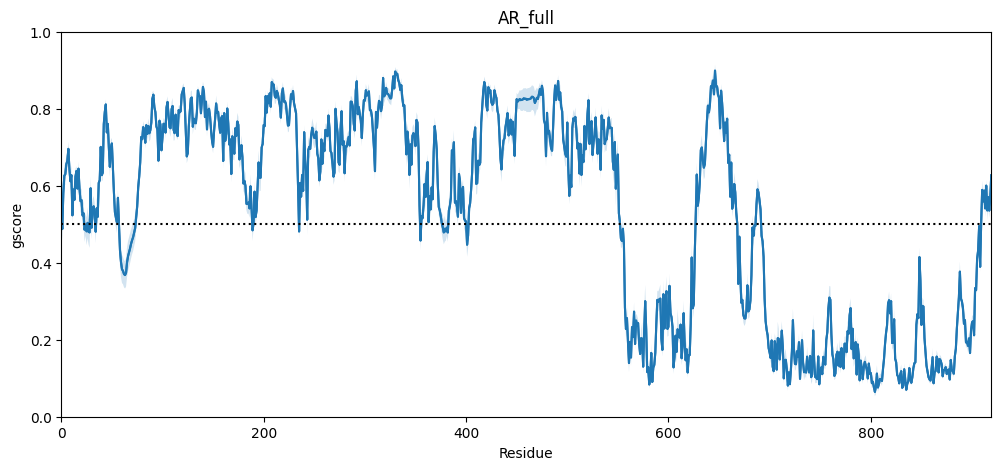

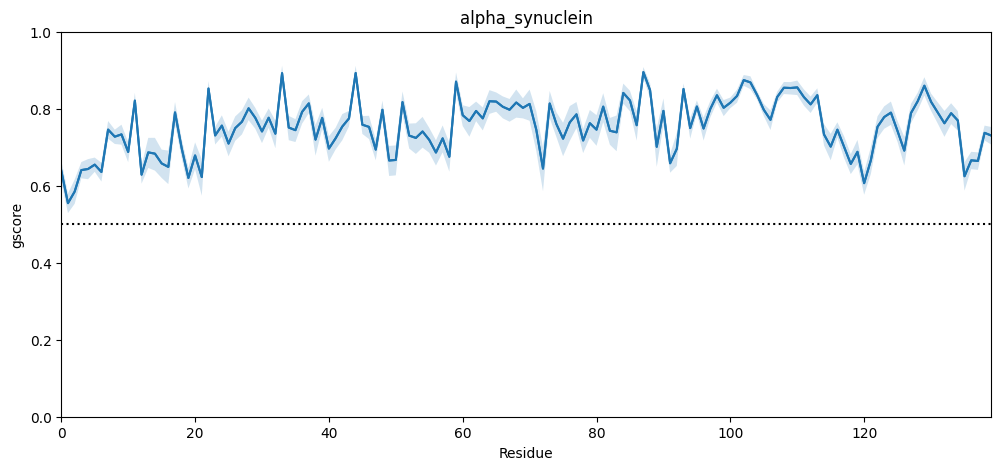

In [22]:
!adopt2g-predict --input ar.fasta --out ar-adopt2g-no.csv --no

df = pd.read_csv(
    "ar-adopt2g-no.csv",
    index_col="label",
    converters={
        "gscores": lambda x: np.asarray(json.loads(x), dtype=float),
        "gscores_lower": lambda x: np.asarray(json.loads(x), dtype=float),
        "gscores_upper": lambda x: np.asarray(json.loads(x), dtype=float),
        "member_gscores": lambda x: np.asarray(json.loads(x), dtype=float),
    },
)

for label, row in df.iterrows():
    gscores = row["gscores"]
    gscores_lower = row["gscores_lower"]
    gscores_upper = row["gscores_upper"]

    plt.figure(figsize=(12, 5))
    plt.title(label)
    plt.plot(gscores)
    plt.fill_between(range(len(gscores)), gscores_lower, gscores_upper, alpha=0.2)
    plt.plot(gscores, c="C0")
    plt.axhline(0.5, color="k", linestyle=":")
    plt.ylim(0, 1)
    plt.margins(x=0)
    plt.xlabel("Residue")
    plt.ylabel("gscore")
    plt.show()

In [26]:
df_saxs = pd.read_csv(
    "../../peptonebench/datasets/PeptoneDB-SAXS/PeptoneDB-SAXS.csv",
    index_col="label",
    converters={"gscores_adopt2": lambda x: np.asarray(json.loads(x), dtype=float)},
)
print(df_saxs.columns)
df_saxs_new = pd.read_csv(
    "PeptoneDB-SAXS-adopt2g.csv",
    index_col="label",
    converters={"gscores": lambda x: np.asarray(json.loads(x), dtype=float)},
)
print(df_saxs_new.columns)

assert df_saxs.index.equals(df_saxs_new.index)

Index(['sequence', 'length', 'pH', 'mean_gscore_adopt2', 'gscores_adopt2'], dtype='object')
Index(['sequence', 'mean_gscore', 'mean_gscore_lower', 'mean_gscore_upper',
       'gscores', 'gscores_lower', 'gscores_upper'],
      dtype='object')


old: tot_disodered=59
new: tot_disodered=64
entry with max diff: SASDB85
  old: 0.5088792934431045
  new: 0.2377275855608294


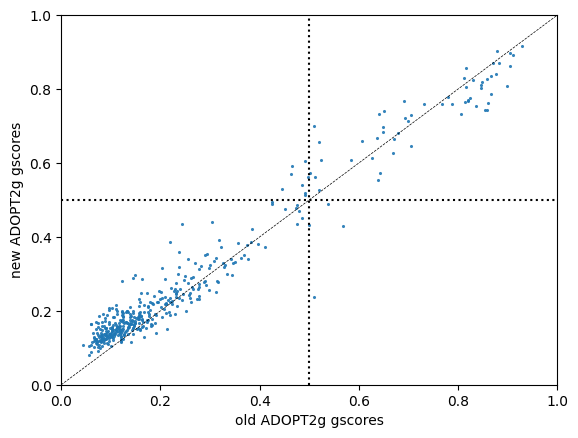

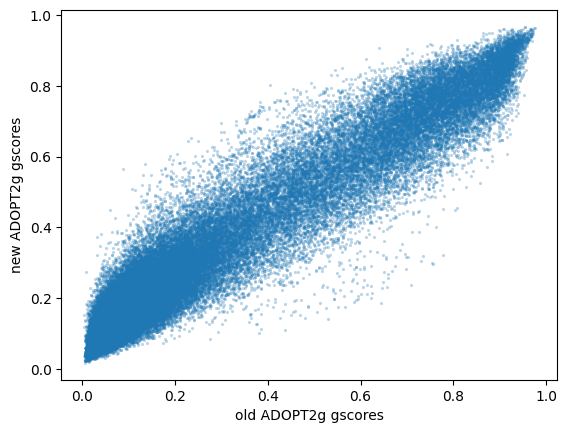

In [24]:
print(f"old: tot_disodered={sum(df_saxs['mean_gscore_adopt2'].values > 0.5)}")
print(f"new: tot_disodered={sum(df_saxs_new['mean_gscore'].values > 0.5)}")
max_diff_label = df_saxs.iloc[
    np.argmax(np.abs(df_saxs["mean_gscore_adopt2"].values - df_saxs_new["mean_gscore"].values))
].name
print(f"entry with max diff: {max_diff_label}")
print(f"  old: {df_saxs.loc[max_diff_label, 'mean_gscore_adopt2']}")
print(f"  new: {df_saxs_new.loc[max_diff_label, 'mean_gscore']}")
plt.scatter(
    df_saxs["mean_gscore_adopt2"].values,
    df_saxs_new["mean_gscore"].values,
    alpha=0.9,
    s=5,
    lw=0,
)
plt.axline((0.5, 0.5), slope=1, color="k", ls="--", lw=0.5)
plt.axhline(0.5, color="k", linestyle=":")
plt.axvline(0.5, color="k", linestyle=":")
plt.xlim(0, 1)
plt.ylim(0, 1)
plt.xlabel("old ADOPT2g gscores")
plt.ylabel("new ADOPT2g gscores")
plt.show()

plt.scatter(
    np.concatenate(df_saxs["gscores_adopt2"].values),
    np.concatenate(df_saxs_new["gscores"].values),
    alpha=0.3,
    s=5,
    lw=0,
)
plt.xlabel("old ADOPT2g gscores")
plt.ylabel("new ADOPT2g gscores")
plt.show()

In [25]:
df = pd.read_csv("../datasets/cleaned_trizod_dataset.csv", index_col="label")
a_syn_seq = "MDVFMKGLSKAKEGVVAAAEKTKQGVAEAAGKTKEGVLYVGSKTKEGVVHGVATVAEKTKEQVTNVGGAVVTGVTAVAQKTVEGAGSIAAATGFVKKDQLGKNEEGAPQEGILEDMPVDPDNEAYEMPSEEGYQDYEPEA"
print(a_syn_seq in df["sequence"].values)
print(np.where(["Syn" in x for x in df["entity_name"].values]))
df.iloc[np.where(["Syn" in x for x in df["entity_name"].values])[0]]

False
(array([ 113,  171,  299,  434,  989,  990, 1611, 1903, 2381, 3389, 3687,
       4141]),)


,is_test,entity_name,cluster_size,sequence,temperature,pH,ionic_strength,total_bbshifts,mean_gscore,gscores
label,,,,,,,,,,
4020_1_1_1,False,Bovine Syncytial Respiratory Virus-G,1,NHQDHNNFQTLPYVPCSTCEGNLACLSLCHIE,285.0,4.6,0.100,134.0,0.283903,"[NaN, 0.4584, 0.5222, 0.4889, 0.5817, 0.6387, ..."
4198_1_1_1,False,N-terminal domain of Syntaxin 1A,1,GSPGISGGGGGIPASMKDRTQELRTAKDSDDDDDVTVTVDRDRFMD...,305.0,6.3,0.100,824.0,0.081919,"[NaN, NaN, NaN, NaN, NaN, NaN, NaN, NaN, NaN, ..."
4591_1_1_1,False,Syndecan 4,2,RMKKKDEGSYDLGKKPIYKKAPTNEFYA,298.0,7.4,0.050,74.0,0.638769,"[NaN, 0.7705, 0.6166, 0.4184, 0.4578, 0.469, 0..."
4954_1_1_1,False,Riboflavin Synthase,1,MFTGIVQGTAKLVSIDEKPNFRTHVVELPDHMLDGLETGASVAHNG...,300.0,7.3,0.125,637.0,0.134574,"[NaN, 0.0701, 0.1063, 0.0868, 0.089, 0.0879, 0..."
6281_1_1_1,False,Synaptobrevin2 SNARE motif,2,NRRLQQTQAQVDEVVDIMRVNVDKVLERDQKLSELDDRADALQAGA...,305.0,7.5,0.100,165.0,0.089629,"[NaN, NaN, NaN, 0.0219, 0.0546, 0.1066, 0.1368..."
6281_2_2_2,False,Syntaxin 1A SNARE motif,2,ALSEIETRHSEIIKLENSIRELHDMFMDMAMLVESQGEMIDRIEYN...,305.0,7.5,0.100,138.0,0.161925,"[NaN, NaN, NaN, NaN, 0.2245, 0.1984, 0.1751, 0..."
11000_1_1_1,False,ATP_Synthase_Epsilon_Chain,1,IDVLRAKAAKERAERRLQSQQDDIDFKRAELALKRAMNRLSVAEMK,303.0,6.8,0.010,170.0,0.196105,"[NaN, 0.0, 0.061, 0.1769, 0.2771, 0.2287, 0.18..."
15095_1_1_1,False,Alpha-Syn12,1,MDVFMKGLSKAK,298.0,6.5,0.100,29.0,0.629840,"[NaN, 0.1883, 0.313, 0.4861, 0.6703, 0.7114, 0..."
16156_1_1_1,False,Synphilin-1,1,GSVETCMSLASQVVKLTKQLKEQTVERVTLQNQLQQFLEAQKSEGKSL,298.0,6.0,0.100,310.0,0.120300,"[NaN, NaN, 0.2473, 0.2361, 0.1324, 0.0882, 0.0..."
